In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, GridSearchCV, cross_val_score, StratifiedKFold)
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, mean_squared_error, r2_score)

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

df = pd.read_csv("/content/diabetes (6) - diabetes (6) (1).csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [4]:
df.shape

(768, 9)

In [5]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [6]:
df.dtypes

,0
Pregnancies,int64
Glucose,int64
BloodPressure,int64
SkinThickness,int64
Insulin,int64
BMI,float64
DiabetesPedigreeFunction,float64
Age,int64
Outcome,int64


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [8]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [9]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [10]:
df.duplicated().sum()

np.int64(0)

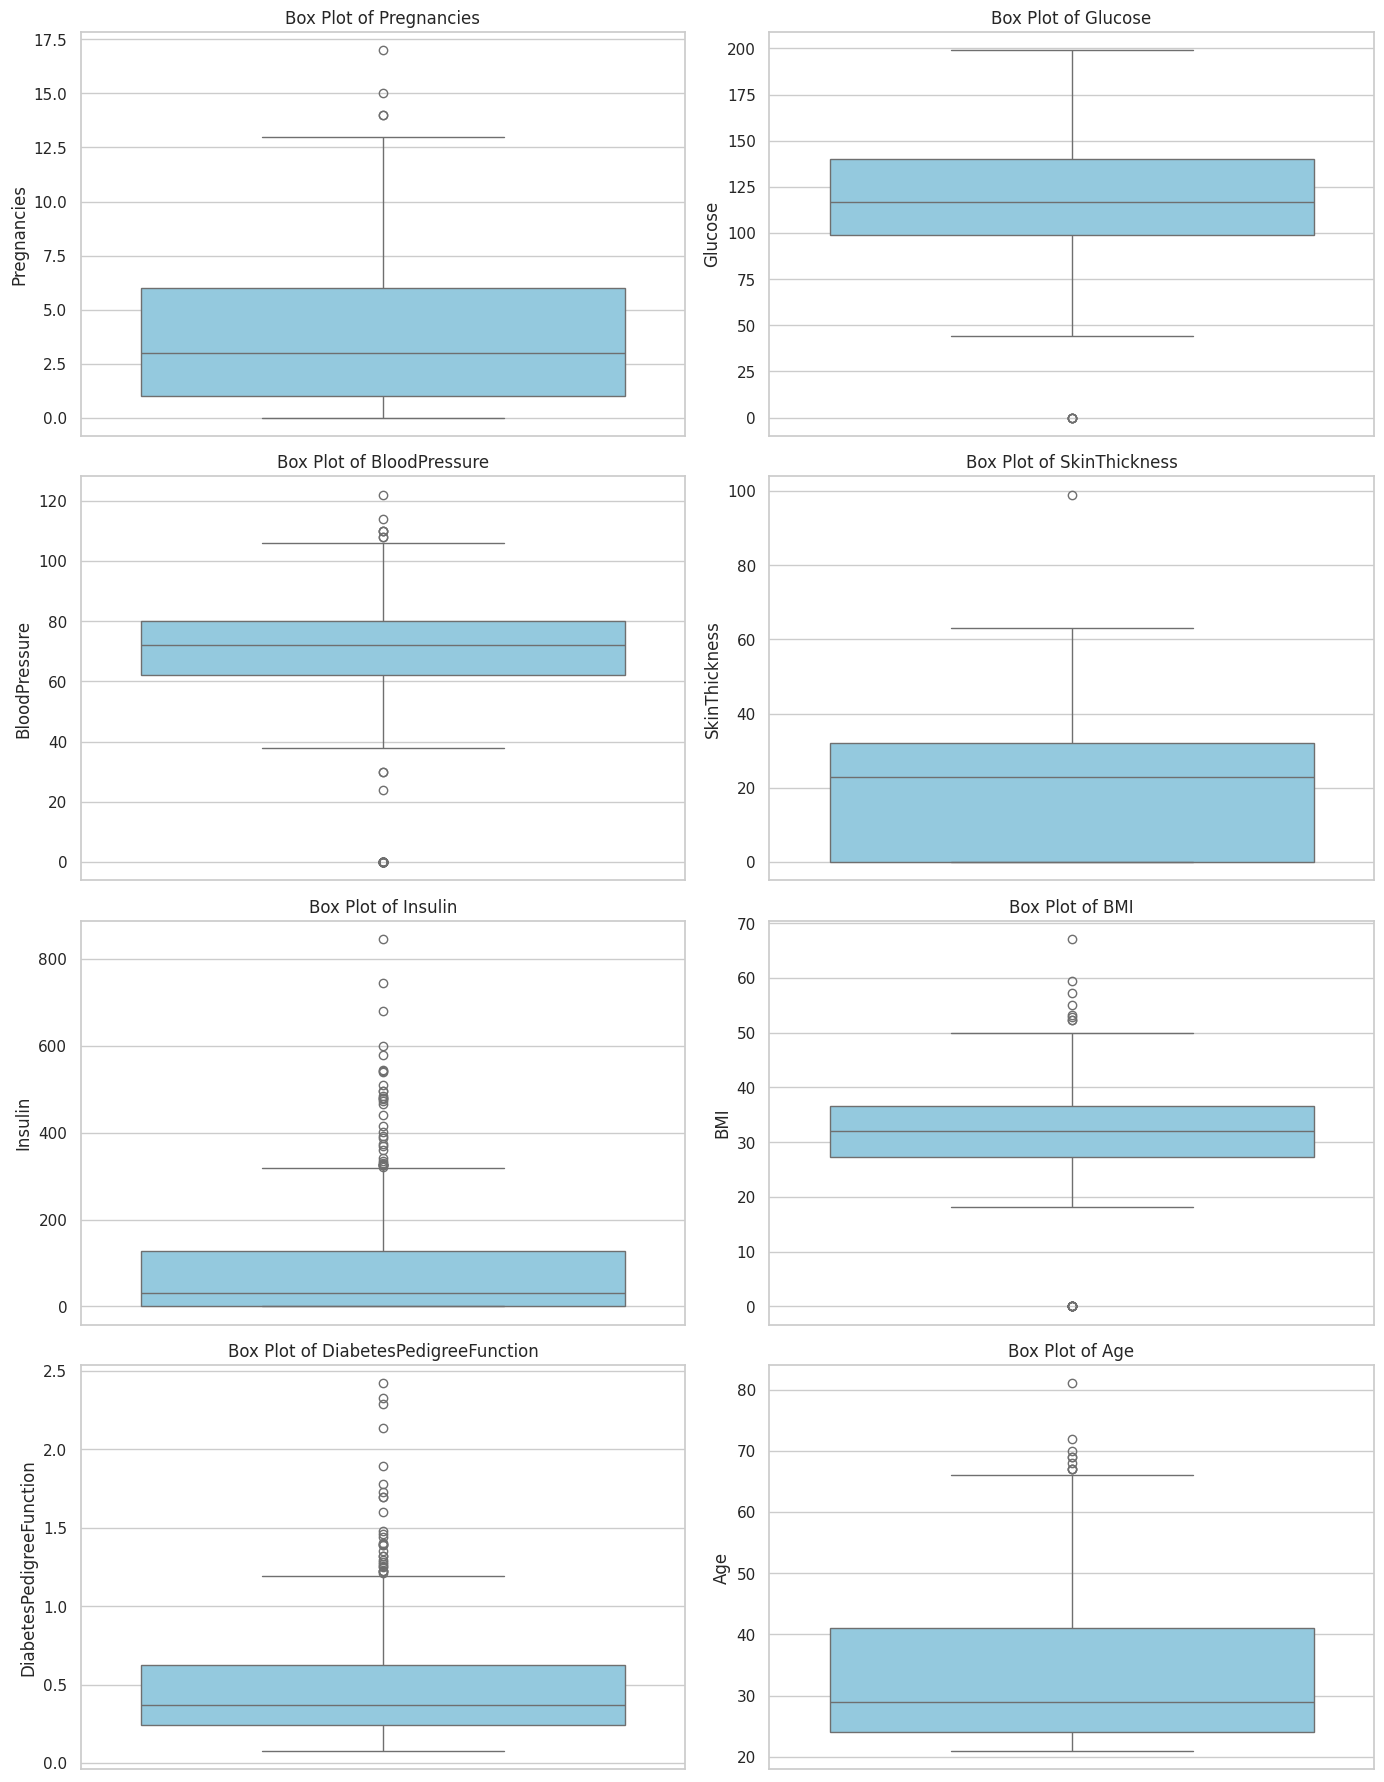

In [11]:
# 1. Box plots
features = [col for col in df.columns if col != "Outcome"]
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(14, 18))
axes = axes.flatten()
for i, col in enumerate(features):
    sns.boxplot(y=df[col], ax=axes[i], color="skyblue")
    axes[i].set_title(f"Box Plot of {col}")
for j in range(len(features), len(axes)):
    axes[j].axis("off")
plt.tight_layout()
plt.show()

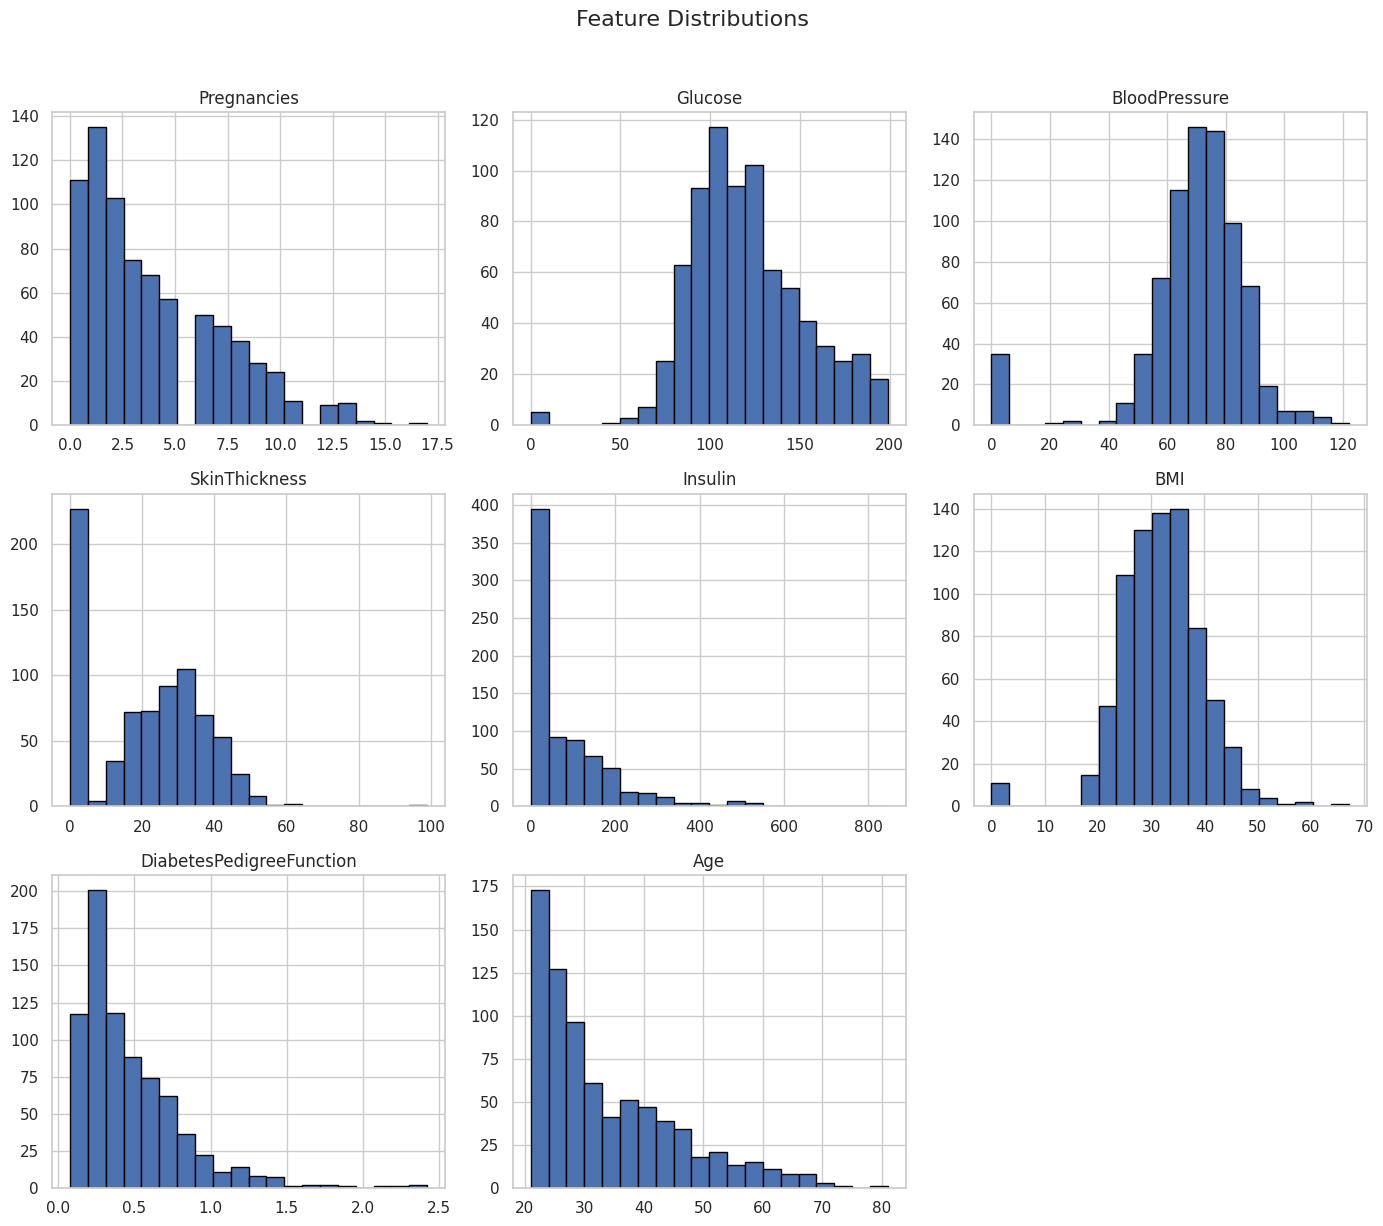

In [12]:
# 2. Histograms
df[features].hist(figsize=(14, 12), bins=20, edgecolor="black")
plt.suptitle("Feature Distributions", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

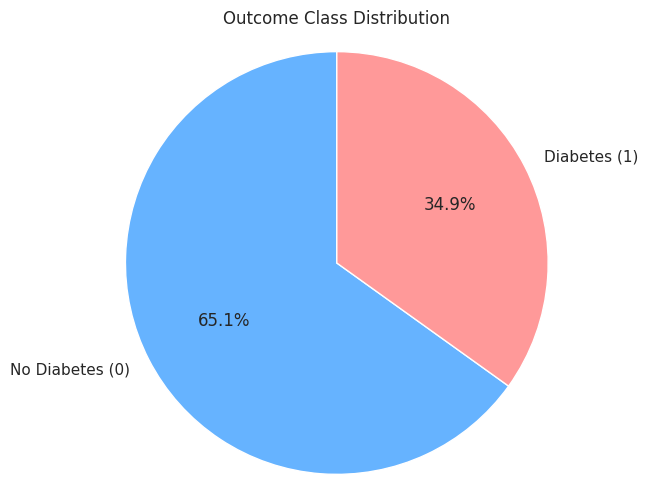

Outcome counts:
Outcome
0    500
1    268
Name: count, dtype: int64


In [13]:
# 3. Pie chart
outcome_counts = df["Outcome"].value_counts().sort_index()
plt.figure(figsize=(6, 6))
plt.pie(outcome_counts, labels=["No Diabetes (0)", "Diabetes (1)"], autopct="%1.1f%%", startangle=90, colors=["#66b3ff", "#ff9999"])
plt.title("Outcome Class Distribution")
plt.axis("equal")
plt.show()
print("Outcome counts:")
print(outcome_counts)

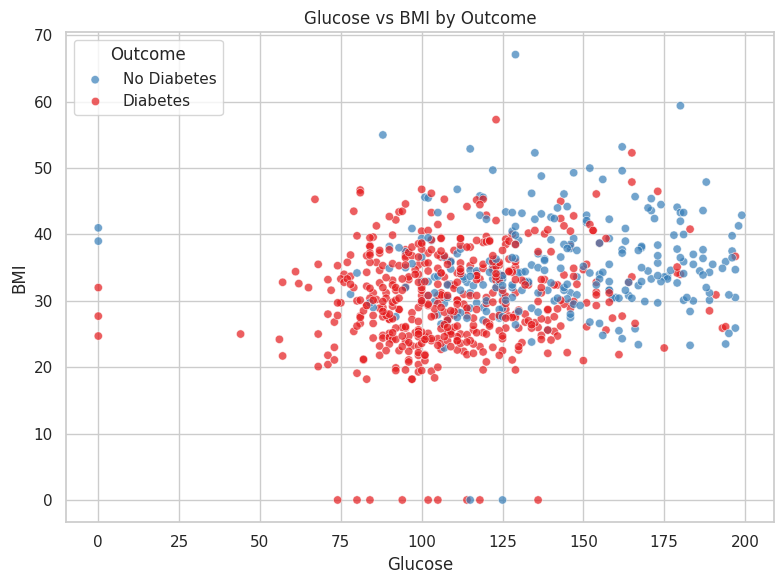

In [14]:
# 4. Scatter plot
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="Glucose", y="BMI", hue="Outcome", alpha=0.7, palette="Set1")
plt.title("Glucose vs BMI by Outcome")
plt.xlabel("Glucose")
plt.ylabel("BMI")
plt.legend(title="Outcome", labels=["No Diabetes", "Diabetes"])
plt.tight_layout()
plt.show()

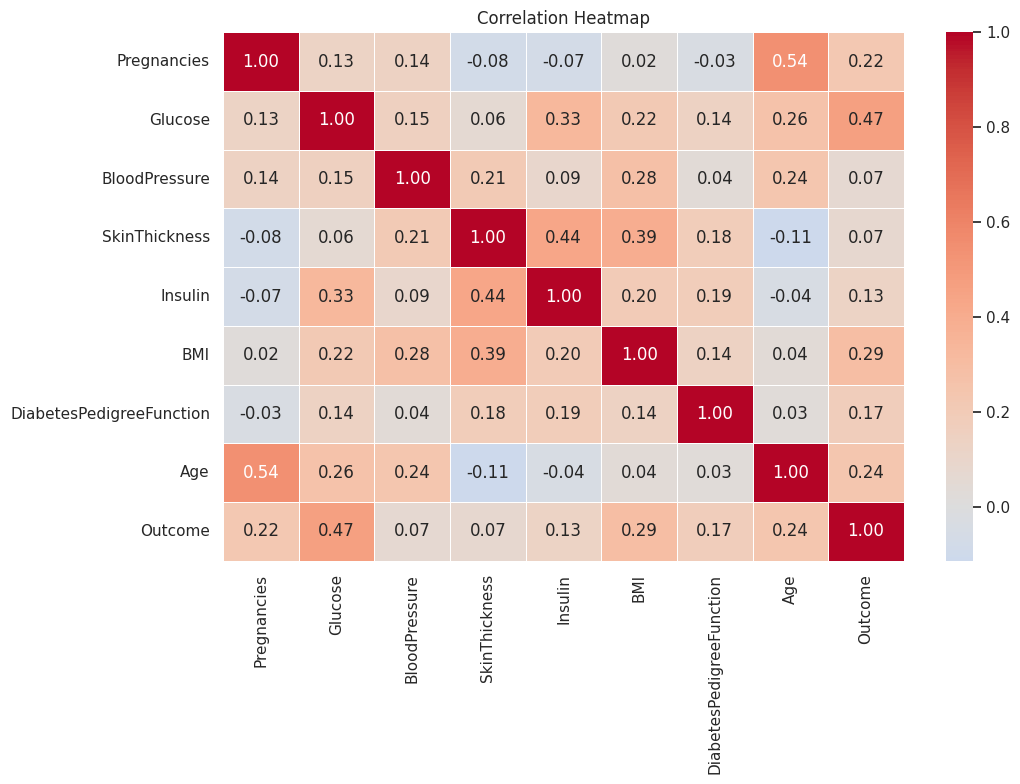

In [15]:
# 5. Correlation heatmap
plt.figure(figsize=(11, 8))
correlation = df.corr(numeric_only=True)
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

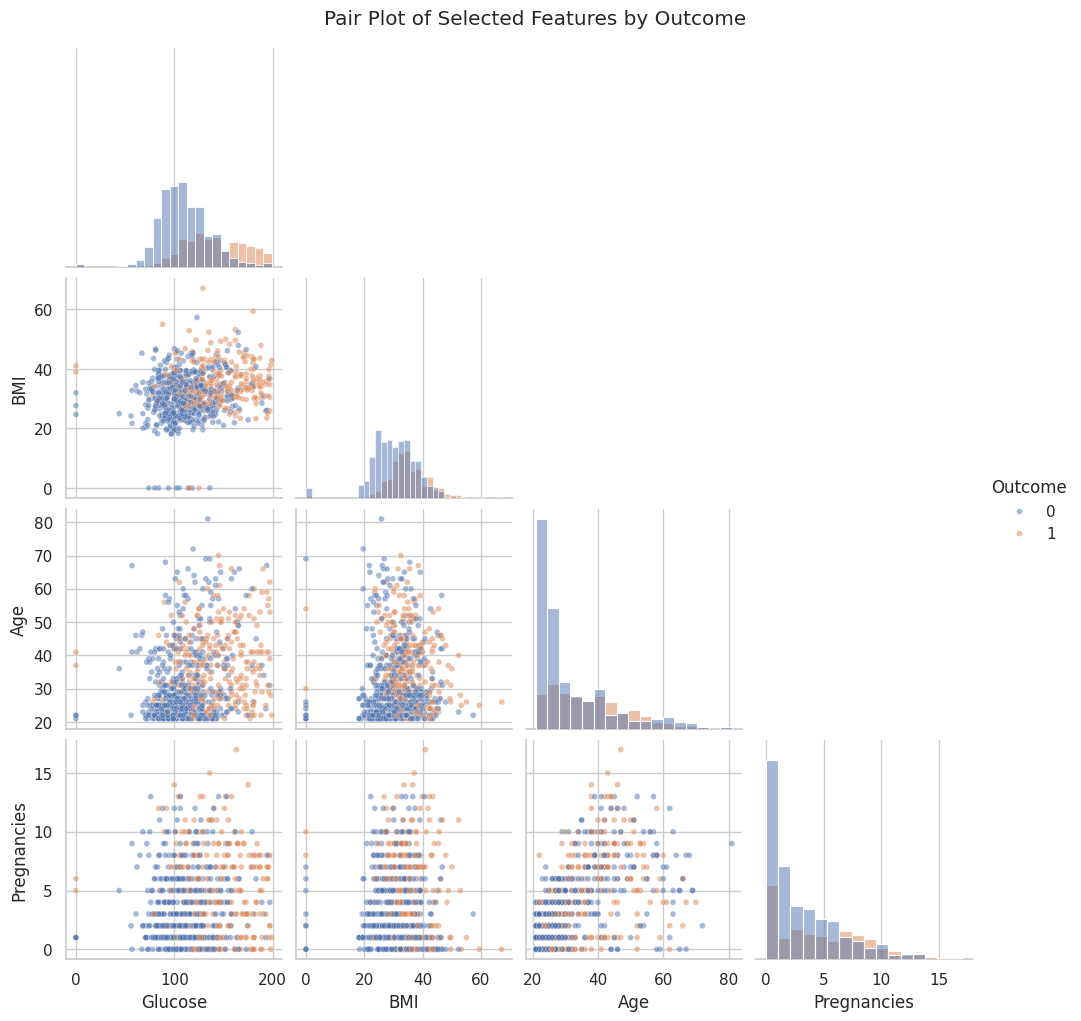

In [16]:
# 6. Pair plot
pairplot_cols = [col for col in ["Glucose", "BMI", "Age", "Pregnancies", "Outcome"] if col in df.columns]
sns.pairplot(df[pairplot_cols], hue="Outcome", diag_kind="hist", corner=True, plot_kws={"alpha": 0.5, "s": 18})
plt.suptitle("Pair Plot of Selected Features by Outcome", y=1.02)
plt.show()

In [17]:
zero_columns = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
zero_counts = (df[zero_columns] == 0).sum()
print("Zero Values: ")
print(zero_counts)

Zero Values: 
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [18]:
df_clean = df.copy()
df_clean[zero_columns] = df_clean[zero_columns].replace(0, np.nan)
print("Missing values after replacing invalid zeroes: ")
print(df_clean.isnull().sum())

Missing values after replacing invalid zeroes: 
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [19]:
for col in zero_columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

print("Missing values after median imputation: ")
print(df_clean.isnull().sum())

Missing values after median imputation: 
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [20]:
x = df_clean.drop("Outcome", axis = 1)
y = df_clean["Outcome"]

print("X shape :", x.shape)
print("Y shape :", y.shape)

X shape : (768, 8)
Y shape : (768,)


In [21]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.20, random_state = 42, stratify = y)

print("Training Samples :", x_train.shape[0])
print("Testing Samples :", x_test.shape[0])

Training Samples : 614
Testing Samples : 154


In [22]:
print("Training Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Distribution:")
print(y_test.value_counts(normalize=True))

Training Distribution:
Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64

Testing Distribution:
Outcome
0    0.649351
1    0.350649
Name: proportion, dtype: float64


In [23]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [24]:
scaler.fit_transform(x_train)
scaler.transform(x_test)

array([[ 0.96054099,  1.24515673, -0.66367599, ..., -0.74014536,
        -0.55579092,  0.56103382],
       [ 1.86648903, -1.79026591,  2.76066903, ...,  0.44778472,
        -0.58306107,  1.15306018],
       [-0.5493724 ,  0.01097389,  0.3147083 , ...,  0.50644793,
         0.01688223, -0.6230189 ],
       ...,
       [-0.5493724 , -1.32327781, -1.64206028, ..., -0.57882152,
         3.70138246, -0.70759409],
       [ 0.05459296,  2.07906404,  0.47777235, ...,  0.66777177,
        -0.64669142, -0.20014293],
       [-0.85135507, -1.69019703,  0.47777235, ...,  0.11047124,
        -0.16794879, -1.04589487]])

In [25]:
comparision = pd.DataFrame({
    "Original Mean" : x_train.mean(),
    "Original Std" : x_train.std(),
    "Scaled Mean" : x_train_scaled.mean(axis = 0),
    "Scaled Std" : x_train_scaled.std(axis = 0)
})

display(comparision)

,Original Mean,Original Std,Scaled Mean,Scaled Std
Pregnancies,3.819218,3.314148,-6.943414e-17,1.0
Glucose,121.671010,30.003794,-1.099374e-16,1.0
BloodPressure,72.140065,12.275119,3.095606e-16,1.0
SkinThickness,29.042345,8.891855,-3.471707e-17,1.0
Insulin,137.705212,78.764767,-4.339634e-18,1.0
BMI,32.446743,6.824142,-1.148556e-15,1.0
DiabetesPedigreeFunction,0.477428,0.330300,-1.099374e-16,1.0
Age,33.366450,11.833438,-1.084908e-16,1.0


In [26]:
K = 5

In [27]:
knn = KNeighborsClassifier(n_neighbors = 5)
knn.fit(x_train_scaled, y_train)

KNeighborsClassifier()

In [28]:
y_pred = knn.predict(x_test_scaled)
print("Predictions :")
print(y_pred[:20])

Predictions :
[1 0 0 1 0 0 0 1 0 1 0 1 0 0 0 1 1 0 1 0]


In [29]:
y_prob = knn.predict_proba(x_test_scaled)[:,1]
print(y_prob[:20])

[0.6 0.2 0.2 0.6 0.  0.2 0.2 0.8 0.  0.6 0.4 0.6 0.  0.  0.  0.6 0.8 0.
 1.  0.2]


In [30]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy : {accuracy:.4f}")

Accuracy : 0.7532


In [31]:
precision = precision_score(y_test, y_pred)
print(f"Precision : {precision:.4f}")

Precision : 0.6600


In [32]:
recall = recall_score(y_test, y_pred)
print(f"Recall : {recall:.4f}")

Recall : 0.6111


In [33]:
f1 = f1_score(y_test, y_pred)
print(f"F1 Score : {f1:.4f}")

F1 Score : 0.6346


In [34]:
print(classification_report(y_test, y_pred, target_names = ["No Diabetes", "Diabetes"]))

              precision    recall  f1-score   support

 No Diabetes       0.80      0.83      0.81       100
    Diabetes       0.66      0.61      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154



In [35]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[83 17]
 [21 33]]


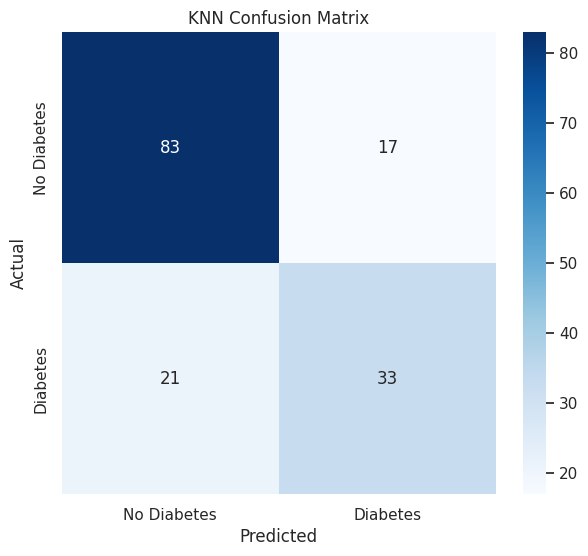

In [36]:
plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["No Diabetes", "Diabetes"], yticklabels=["No Diabetes", "Diabetes"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN Confusion Matrix")
plt.show()

In [37]:
k_values = range(1,21)

train_accuracy = []
test_accuracy = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors = k)
    model.fit(x_train_scaled, y_train)
    train_accuracy.append(model.score(x_train_scaled, y_train))
    test_accuracy.append(model.score(x_test_scaled, y_test))

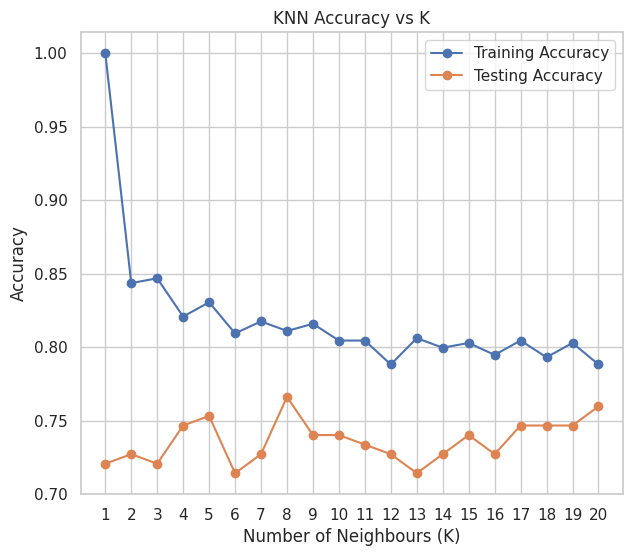

In [38]:
plt.figure(figsize=(7,6))
plt.plot(k_values, train_accuracy, marker="o", label="Training Accuracy")
plt.plot(k_values, test_accuracy, marker="o", label="Testing Accuracy")

plt.xlabel("Number of Neighbours (K)")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy vs K")
plt.xticks(k_values)
plt.legend()

plt.show()

In [39]:
best_k_accuracy = k_values[np.argmax(test_accuracy)]
best_accuracy = max(test_accuracy)

print("Best K :", best_k_accuracy)
print("Best Test Accuracy :", best_accuracy)


Best K : 8
Best Test Accuracy : 0.7662337662337663


In [40]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = []
for k in range(1,31):
    model = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(model, x_train_scaled, y_train, cv=cv, scoring="accuracy")
    cv_scores.append(scores.mean())

In [41]:
best_k_cv = np.argmax(cv_scores) + 1
print("Best K based on Cross Validation :", best_k_cv)
print("Best CV Accuracy :", max(cv_scores))

Best K based on Cross Validation : 13
Best CV Accuracy : 0.7703718512594963


In [42]:
param_grid = {"n_neighbors": list(range(3,31,2)), "weights":["uniform","distance"],
              "metric" : ["euclidean","manhattan","minkowski"],
             "p":[1,2]}

In [43]:
grid_search = GridSearchCV(estimator=KNeighborsClassifier(), param_grid=param_grid, cv=5,
                          scoring="accuracy",n_jobs=-1)
grid_search.fit(x_train_scaled, y_train)
print("Grid Search Completed")

Grid Search Completed


In [44]:
print("Best Parameters:")
print(grid_search.best_params_)

Best Parameters:
{'metric': 'euclidean', 'n_neighbors': 19, 'p': 1, 'weights': 'uniform'}


In [45]:
print("Best Cross Validation Accuracy : ", grid_search.best_score_)

Best Cross Validation Accuracy :  0.7769025723044115


In [46]:
best_knn = grid_search.best_estimator_
print(best_knn)

KNeighborsClassifier(metric='euclidean', n_neighbors=19, p=1)


In [47]:
final_pred = best_knn.predict(x_test_scaled)
final_prob = best_knn.predict_proba(x_test_scaled)[:,1]

In [48]:
final_accuracy = accuracy_score(y_test, final_pred)
final_precision = precision_score(y_test, final_pred, zero_division=0)
final_recall = recall_score(y_test, final_pred, zero_division=0)
final_f1 = f1_score(y_test, final_pred, zero_division=0)

print("Final Tuned KNN Classification Metrics")
print(f"Accuracy  : {final_accuracy:.4f}")
print(f"Precision : {final_precision:.4f}")
print(f"Recall    : {final_recall:.4f}")
print(f"F1 Score  : {final_f1:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, final_pred, target_names=["No Diabetes", "Diabetes"], zero_division=0))
print("Final prediction probabilities (first 20):")
print(final_prob[:20])

Final Tuned KNN Classification Metrics
Accuracy  : 0.7468
Precision : 0.6667
Recall    : 0.5556
F1 Score  : 0.6061

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.78      0.85      0.81       100
    Diabetes       0.67      0.56      0.61        54

    accuracy                           0.75       154
   macro avg       0.72      0.70      0.71       154
weighted avg       0.74      0.75      0.74       154

Final prediction probabilities (first 20):
[0.63157895 0.15789474 0.21052632 0.36842105 0.10526316 0.10526316
 0.31578947 0.78947368 0.         0.63157895 0.42105263 0.31578947
 0.10526316 0.26315789 0.10526316 0.42105263 0.57894737 0.
 0.78947368 0.10526316]


## KNN Regression: Predicting BMI

In [49]:
# Prepare features and target for regression.
X_reg = df_clean.drop(["BMI", "Outcome"], axis=1)
y_reg = df_clean["BMI"]

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42
)

# Scale features using the training set only to avoid data leakage.
scaler_reg = StandardScaler()
X_train_r_scaled = scaler_reg.fit_transform(X_train_r)
X_test_r_scaled = scaler_reg.transform(X_test_r)

print("Regression training samples:", X_train_r.shape[0])
print("Regression testing samples:", X_test_r.shape[0])
print("Regression feature columns:", list(X_reg.columns))

Regression training samples: 614
Regression testing samples: 154
Regression feature columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'DiabetesPedigreeFunction', 'Age']


Best K for Regression (by R-squared): 18
Best test R-squared: 0.2407


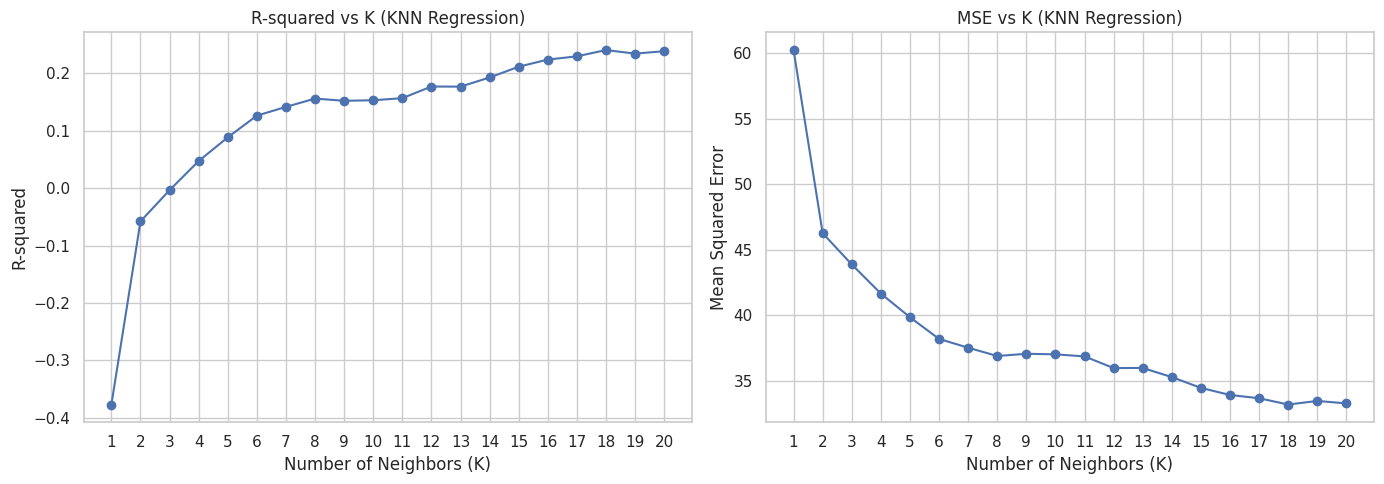

In [50]:
# Compare K values using R-squared and MSE on the held-out test set.
k_values_reg = range(1, 21)
r2_scores = []
mse_scores = []

for k in k_values_reg:
    reg = KNeighborsRegressor(n_neighbors=k)
    reg.fit(X_train_r_scaled, y_train_r)
    pred_r = reg.predict(X_test_r_scaled)
    r2_scores.append(r2_score(y_test_r, pred_r))
    mse_scores.append(mean_squared_error(y_test_r, pred_r))

best_k_r = list(k_values_reg)[int(np.argmax(r2_scores))]
print(f"Best K for Regression (by R-squared): {best_k_r}")
print(f"Best test R-squared: {max(r2_scores):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(list(k_values_reg), r2_scores, marker="o")
axes[0].set_title("R-squared vs K (KNN Regression)")
axes[0].set_xlabel("Number of Neighbors (K)")
axes[0].set_ylabel("R-squared")
axes[0].set_xticks(list(k_values_reg))
axes[1].plot(list(k_values_reg), mse_scores, marker="o")
axes[1].set_title("MSE vs K (KNN Regression)")
axes[1].set_xlabel("Number of Neighbors (K)")
axes[1].set_ylabel("Mean Squared Error")
axes[1].set_xticks(list(k_values_reg))
plt.tight_layout()
plt.show()

Final KNN Regression Metrics
Best K   : 18
MSE      : 33.2113
RMSE     : 5.7629
R-squared: 0.2407


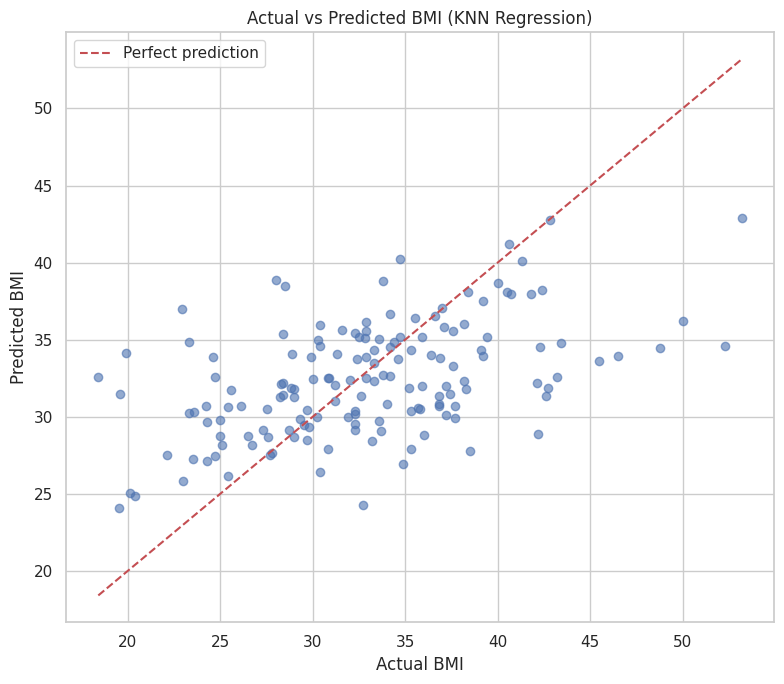

In [51]:
# Train the final KNN regressor and report evaluation metrics.
best_reg = KNeighborsRegressor(n_neighbors=best_k_r)
best_reg.fit(X_train_r_scaled, y_train_r)
y_pred_best_r = best_reg.predict(X_test_r_scaled)

reg_mse = mean_squared_error(y_test_r, y_pred_best_r)
reg_rmse = np.sqrt(reg_mse)
reg_r2 = r2_score(y_test_r, y_pred_best_r)

print("Final KNN Regression Metrics")
print(f"Best K   : {best_k_r}")
print(f"MSE      : {reg_mse:.4f}")
print(f"RMSE     : {reg_rmse:.4f}")
print(f"R-squared: {reg_r2:.4f}")

# Actual versus predicted BMI; the dashed diagonal represents perfect predictions.
plt.figure(figsize=(8, 7))
plt.scatter(y_test_r, y_pred_best_r, alpha=0.6)
line_min = min(y_test_r.min(), y_pred_best_r.min())
line_max = max(y_test_r.max(), y_pred_best_r.max())
plt.plot([line_min, line_max], [line_min, line_max], "r--", label="Perfect prediction")
plt.xlabel("Actual BMI")
plt.ylabel("Predicted BMI")
plt.title("Actual vs Predicted BMI (KNN Regression)")
plt.legend()
plt.tight_layout()
plt.show()